In [1]:
import os, pandas as pd
print(os.getcwd())                    
print(os.listdir("../data"))          

rd = dict(sep=r"\s+", header=None, names=["ra","dec"], usecols=[0,1])
rings = pd.read_csv("../data/train_rings_pos.dat", **rd)
norings = pd.read_csv("../data/train_norings_pos.dat", **rd)

/media/user/euclid cutouts/notebooks
['train_rings_pos.dat', 'train_norings_pos.dat']


In [2]:
import pandas as pd, numpy as np, astropy.units as u
from astropy.coordinates import SkyCoord

fields = {"EDF-N": (269.7, 66.0), "EDF-F": (52.9, -28.1), "EDF-S": (61.2, -48.4)}

def near_fields(df, radius_deg=5):
    c = SkyCoord(df.ra.values*u.deg, df.dec.values*u.deg)
    out = pd.Series("", index=df.index)
    for name, (ra, dec) in fields.items():
        sep = c.separation(SkyCoord(ra*u.deg, dec*u.deg)).deg
        out[sep < radius_deg] = name
    return out

rings["field"]   = near_fields(rings)
norings["field"] = near_fields(norings)
print(rings.field.value_counts())
print(norings.field.value_counts())

field
         5133
EDF-S      26
EDF-N      11
EDF-F       3
Name: count, dtype: int64
field
         14989
EDF-N       11
Name: count, dtype: int64


In [4]:
from astroquery.esa.euclid.core import Euclid
Euclid.login() 

cand = rings[rings.field != ""]
out = []
for i, r in cand.iterrows():
    q = f"""SELECT object_id, right_ascension, declination, segmentation_area
            FROM catalogue.mer_catalogue
            WHERE 1=CONTAINS(POINT('ICRS', right_ascension, declination),
                             CIRCLE('ICRS', {r.ra}, {r.dec}, {3/3600}))"""
    res = Euclid.launch_job(q).get_results().to_pandas()
    res["desi_idx"] = i
    out.append(res)

hits = pd.concat(out, ignore_index=True)
print(len(hits), hits.desi_idx.nunique())

INFO: Login to Euclid TAP server: eas.esac.esa.int:443/tap-server/tap/ [astroquery.esa.euclid.core]


User:  nsuthar
Password:  ········


INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid data service: eas.esac.esa.int:443/sas-dd/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid cutout service: eas.esac.esa.int:443/sas-cutout/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
9 9


In [5]:
%load_ext autoreload
%autoreload 2

In [6]:
import sys, os, re, glob
sys.path.append("/media/user/Getting started")  
import cutout_utils as ut
import astropy.units as u
from astropy.io import fits

In [7]:
ids = ",".join(str(i) for i in hits.object_id.unique())
query = f"""(SELECT right_ascension, declination, segmentation_area, flux_vis_1fwhm_aper,
            ellipticity, kron_radius, segmentation_map_id
            FROM catalogue.mer_catalogue WHERE object_id IN ({ids}))"""

cutout_folder = "../outputs/seed_cutouts/"
os.makedirs(cutout_folder, exist_ok=True)

df = ut.getFiles(product_type="mosaic", sources=query,
                 instrument_name="VIS", segmentation_map_id=True)
print(len(df), "sources found")                      # expect 9
ut.makeCutoutsByTile(df, output_location=cutout_folder, cutout_size=0.8*u.arcmin)

INFO: Login to Euclid TAP server: eas.esac.esa.int:443/tap-server/tap/ [astroquery.esa.euclid.core]


User:  nsuthar
Password:  ········


INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid data service: eas.esac.esa.int:443/sas-dd/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid cutout service: eas.esac.esa.int:443/sas-cutout/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Query finished. [astroquery.utils.tap.core]
Found 9 query results
9 sources found


Number of files processed:   0%|          | 0/9 [00:00<?, ?it/s]

Made cutout MOSAIC-VIS_TILE102020063-CUTOUT_62.1676126_-49.5831454.fits
Made cutout MOSAIC-VIS_TILE102020529-CUTOUT_56.8647445_-49.015412.fits
Made cutout MOSAIC-VIS_TILE102020539-CUTOUT_64.041135_-49.2306577.fits
Made cutout MOSAIC-VIS_TILE102021019-CUTOUT_64.8825391_-48.2850291.fits
Made cutout MOSAIC-VIS_TILE102021497-CUTOUT_61.0912324_-47.9500333.fits
Made cutout MOSAIC-VIS_TILE102041657-CUTOUT_52.8778459_-30.213104.fits
Made cutout MOSAIC-VIS_TILE102158270-CUTOUT_265.4157552_64.498891.fits
Made cutout MOSAIC-VIS_TILE102158580-CUTOUT_263.7610296_65.0642398.fits
Made cutout MOSAIC-VIS_TILE102160056-CUTOUT_265.7876684_67.5416602.fits
Created a total of 9 cutouts


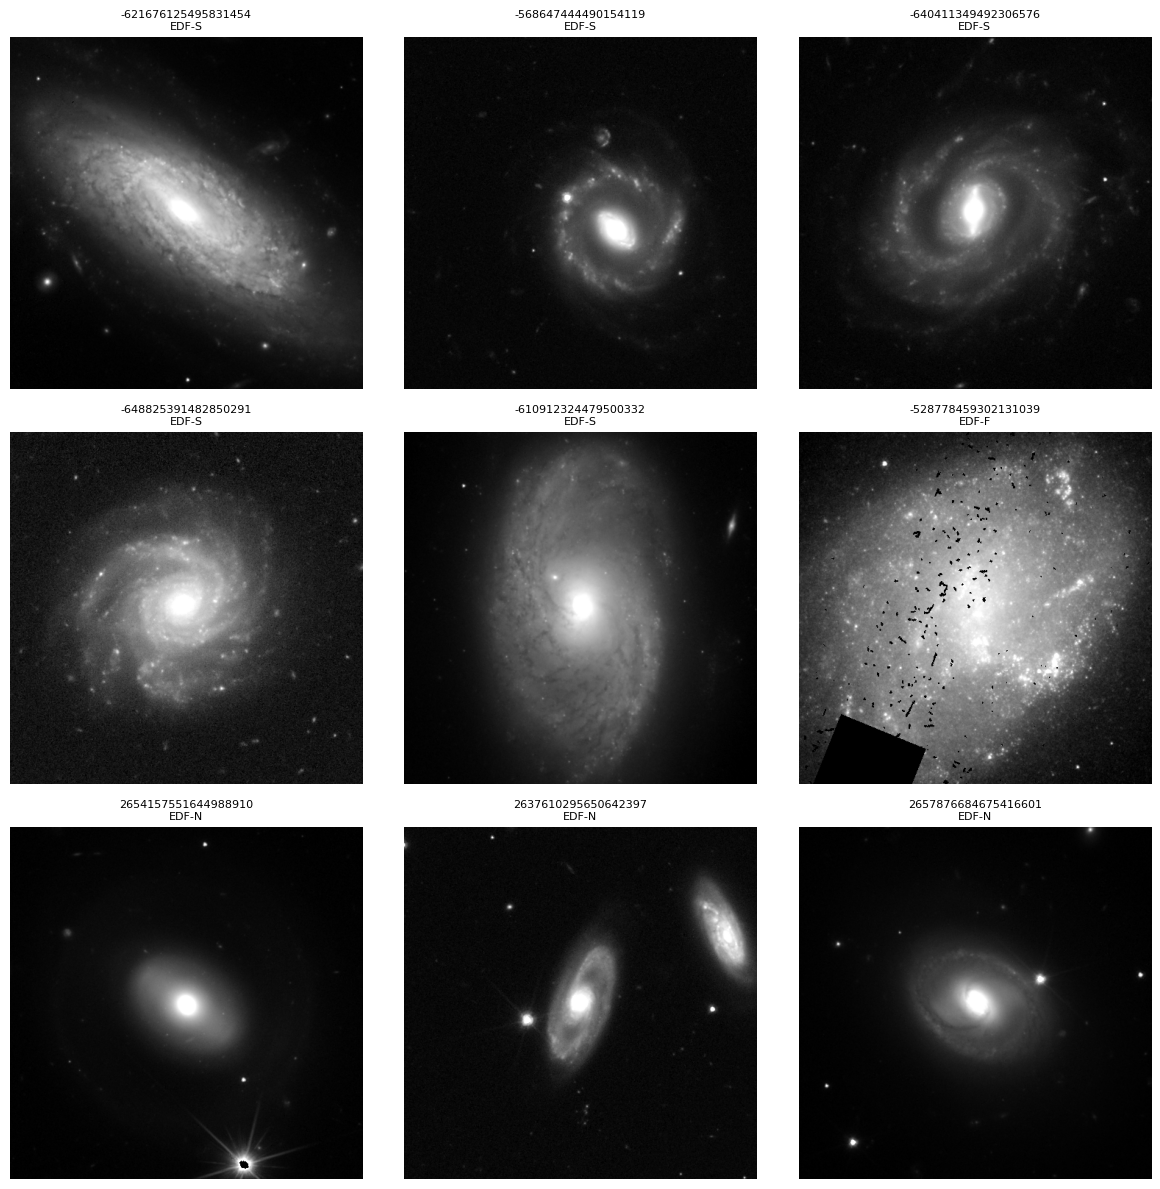

In [8]:
import numpy as np, matplotlib.pyplot as plt
from astropy.visualization import ImageNormalize, PercentileInterval, AsinhStretch

files = sorted(glob.glob(cutout_folder + "*MOSAIC-VIS*.fits"))
rows = []
for f in files:
    ra, dec = map(float, re.search(r"CUTOUT_(-?[\d.]+)_(-?[\d.]+)\.fits", f).groups())
    k = np.argmin((hits.right_ascension-ra)**2 + (hits.declination-dec)**2)
    rows.append((f, hits.object_id.iloc[k], hits.desi_idx.iloc[k]))

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for ax, (f, oid, di) in zip(axes.flat, rows):
    img = fits.getdata(f, ext=0)
    ax.imshow(img, cmap="gray", origin="lower",
              norm=ImageNormalize(img, interval=PercentileInterval(99.5), stretch=AsinhStretch()))
    ax.set_title(f"{oid}\n{cand.loc[di, 'field']}", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.savefig("../outputs/seed_cutouts_grid.png", dpi=150)

In [9]:
hits.to_csv("../data/seed_hits.csv", index=False)   # adjust the path to your data folder
print(hits[["object_id"]])

             object_id
0  -528778459302131039
1  -568647444490154119
2  -610912324479500332
3  -621676125495831454
4  -640411349492306576
5  -648825391482850291
6  2637610295650642397
7  2654157551644988910
8  2657876684675416601
